# LAB 05 - Bài 20: Ảnh hưởng của sequence length

Thí nghiệm giữ cố định LSTM, vocabulary, split, optimizer, batch size và số epoch; chỉ thay đổi `max_length` thành 50, 100, 200.




In [1]:
# ============================================================
# BÀI 20 - EXPERIMENT 5: CHUẨN BỊ DỮ LIỆU IMDb
# Cố định train/validation/test split và tokenizer.
# ============================================================

from pathlib import Path
import tarfile
import urllib.request
import numpy as np
import tensorflow as tf
from sklearn.model_selection import train_test_split
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

DATA_URL = "https://ai.stanford.edu/~amaas/data/sentiment/aclImdb_v1.tar.gz"
DATA_DIR = Path("/content/aclImdb")
ARCHIVE_PATH = Path("/content/aclImdb_v1.tar.gz")

# Tải và giải nén nếu dataset chưa có trong runtime Colab.
if not (DATA_DIR / "train" / "pos").exists():
    if not ARCHIVE_PATH.exists():
        print("Đang tải ACL IMDb từ Stanford (~84 MB)...")
        urllib.request.urlretrieve(DATA_URL, ARCHIVE_PATH)
    print("Đang giải nén dataset...")
    with tarfile.open(ARCHIVE_PATH, "r:gz") as archive:
        archive.extractall(path="/content")

def read_split(split):
    texts, labels = [], []
    for label_name, label_id in (("neg", 0), ("pos", 1)):
        folder = DATA_DIR / split / label_name
        for file_path in sorted(folder.glob("*.txt")):
            texts.append(file_path.read_text(encoding="utf-8", errors="replace").strip())
            labels.append(label_id)
    return texts, np.asarray(labels, dtype=np.int32)

all_train_texts, all_train_labels = read_split("train")
test_texts, y_test = read_split("test")

train_texts, val_texts, y_train, y_val = train_test_split(
    all_train_texts,
    all_train_labels,
    test_size=0.1,
    random_state=42,
    stratify=all_train_labels,
)

MAX_VOCAB_SIZE = 20_000
MAX_LENGTHS = [50, 100, 200]
EMBEDDING_DIM = 64
HIDDEN_SIZE = 64
BATCH_SIZE = 64
EPOCHS = 3
LEARNING_RATE = 0.001
SEED = 42

# Dùng cùng một vocabulary ở cả ba thí nghiệm.
tokenizer = Tokenizer(num_words=MAX_VOCAB_SIZE, oov_token="<OOV>")
tokenizer.fit_on_texts(train_texts)
vocab_size = min(MAX_VOCAB_SIZE, len(tokenizer.word_index) + 1)
train_sequences = tokenizer.texts_to_sequences(train_texts)
val_sequences = tokenizer.texts_to_sequences(val_texts)
test_sequences = tokenizer.texts_to_sequences(test_texts)

total_train_tokens = sum(len(sequence) for sequence in train_sequences)
print("Vocabulary size:", vocab_size)
print("Train/validation/test samples:", len(train_texts), len(val_texts), len(test_texts))
print("Tổng token trong train trước truncation:", total_train_tokens)


Đang tải ACL IMDb từ Stanford (~84 MB)...
Đang giải nén dataset...


/tmp/ipykernel_527/2190800646.py:26: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  archive.extractall(path="/content")


Vocabulary size: 20000
Train/validation/test samples: 22500 2500 25000
Tổng token trong train trước truncation: 5342796



================== max_length = 50 ==================
Epoch 1/3
352/352 - 23s - 65ms/step - accuracy: 0.7260 - loss: 0.5290 - val_accuracy: 0.7764 - val_loss: 0.4748
Epoch 2/3
352/352 - 20s - 57ms/step - accuracy: 0.8542 - loss: 0.3456 - val_accuracy: 0.7780 - val_loss: 0.5421
Epoch 3/3
352/352 - 19s - 53ms/step - accuracy: 0.9020 - loss: 0.2532 - val_accuracy: 0.7564 - val_loss: 0.6487

================== max_length = 100 ==================
Epoch 1/3
352/352 - 36s - 102ms/step - accuracy: 0.7603 - loss: 0.4815 - val_accuracy: 0.8092 - val_loss: 0.4499
Epoch 2/3
352/352 - 33s - 95ms/step - accuracy: 0.8892 - loss: 0.2847 - val_accuracy: 0.7920 - val_loss: 0.5666
Epoch 3/3
352/352 - 34s - 96ms/step - accuracy: 0.9120 - loss: 0.2347 - val_accuracy: 0.7932 - val_loss: 0.4755

================== max_length = 200 ==================
Epoch 1/3
352/352 - 66s - 186ms/step - accuracy: 0.7613 - loss: 0.4883 - val_accuracy: 0.8460 - val_loss: 0.3604
Epoch 2/3
352/352 - 81s - 230ms/step - accuracy

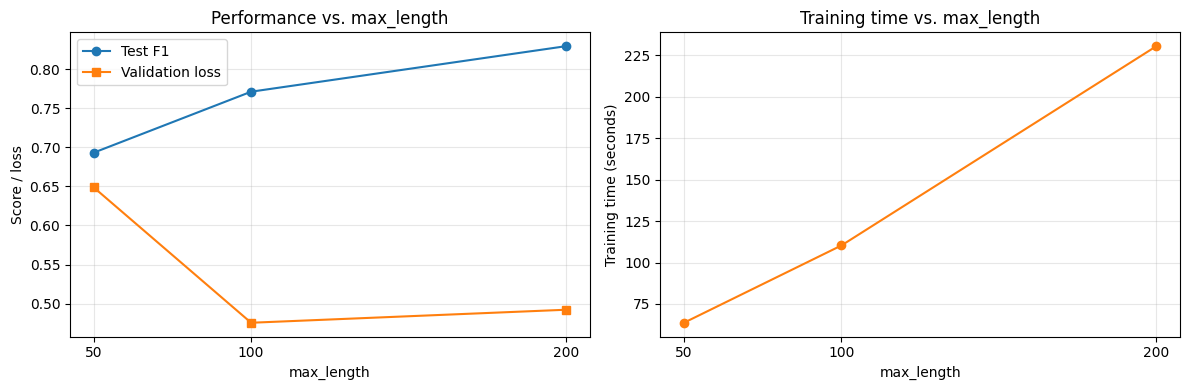

Đã lưu bảng kết quả: /content/lab05_bai20_results.csv


In [2]:
# ============================================================
# BÀI 20 - THÍ NGHIỆM ĐỘ DÀI CHUỖI
# Cùng một LSTM, optimizer, batch size, epoch và data split.
# Chỉ thay đổi max_length = 50, 100, 200.
# ============================================================

import gc
import time
import pandas as pd
import matplotlib.pyplot as plt
from tensorflow.keras import layers, models
from sklearn.metrics import f1_score

results = []

for max_len in MAX_LENGTHS:
    print(f"\n{'=' * 18} max_length = {max_len} {'=' * 18}")
    tf.keras.backend.clear_session()
    gc.collect()
    tf.keras.utils.set_random_seed(SEED)

    # Tính % token train được giữ lại sau truncation.
    retained_tokens = sum(min(len(sequence), max_len) for sequence in train_sequences)
    retained_percent = 100 * retained_tokens / total_train_tokens

    # Post-padding thêm 0 ở cuối; post-truncation cắt phần cuối nếu quá dài.
    X_train = pad_sequences(train_sequences, maxlen=max_len, padding="post", truncating="post")
    X_val = pad_sequences(val_sequences, maxlen=max_len, padding="post", truncating="post")
    X_test = pad_sequences(test_sequences, maxlen=max_len, padding="post", truncating="post")

    # Ước lượng bộ nhớ của ba mảng padded đầu vào; không bao gồm model/runtime/GPU.
    padded_input_memory_mb = (X_train.nbytes + X_val.nbytes + X_test.nbytes) / (1024 ** 2)

    # Kiến trúc và các hyperparameter được giữ nguyên giữa các lần chạy.
    model = models.Sequential([
        layers.Input(shape=(max_len,)),
        layers.Embedding(vocab_size, EMBEDDING_DIM, mask_zero=True),
        layers.LSTM(HIDDEN_SIZE),
        layers.Dense(1, activation="sigmoid"),
    ])
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=LEARNING_RATE),
        loss="binary_crossentropy",
        metrics=["accuracy"],
    )

    start_time = time.perf_counter()
    history = model.fit(
        X_train,
        y_train,
        validation_data=(X_val, y_val),
        epochs=EPOCHS,
        batch_size=BATCH_SIZE,
        shuffle=True,
        verbose=2,
    )
    training_time = time.perf_counter() - start_time
    final_val_loss = history.history["val_loss"][-1]

    test_probabilities = model.predict(X_test, batch_size=BATCH_SIZE, verbose=0).ravel()
    test_predictions = (test_probabilities >= 0.5).astype(np.int32)
    test_f1 = f1_score(y_test, test_predictions, zero_division=0)

    results.append({
        "max_length": max_len,
        "tokens_retained_percent": retained_percent,
        "training_time_seconds": training_time,
        "validation_loss": final_val_loss,
        "test_f1": test_f1,
        "padded_input_memory_mb": padded_input_memory_mb,
    })

results_df = pd.DataFrame(results)
print("\nKết quả Bài 20:")
print(results_df.round(4).to_string(index=False))

# Biểu đồ performance (F1 và validation loss) theo max_length.
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(results_df["max_length"], results_df["test_f1"], marker="o", label="Test F1")
axes[0].plot(results_df["max_length"], results_df["validation_loss"], marker="s", label="Validation loss")
axes[0].set_title("Performance vs. max_length")
axes[0].set_xlabel("max_length")
axes[0].set_ylabel("Score / loss")
axes[0].set_xticks(MAX_LENGTHS)
axes[0].grid(True, alpha=0.3)
axes[0].legend()

axes[1].plot(results_df["max_length"], results_df["training_time_seconds"], marker="o", color="tab:orange")
axes[1].set_title("Training time vs. max_length")
axes[1].set_xlabel("max_length")
axes[1].set_ylabel("Training time (seconds)")
axes[1].set_xticks(MAX_LENGTHS)
axes[1].grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Bảng kết quả để lưu và dùng trong báo cáo.
OUTPUT_CSV = "/content/lab05_bai20_results.csv"
results_df.to_csv(OUTPUT_CSV, index=False)
print("Đã lưu bảng kết quả:", OUTPUT_CSV)

# Khi phân tích, xem trade-off giữa context/token retention với thời gian và bộ nhớ.
# Padded input memory chỉ là kích thước các mảng đầu vào, không phải peak GPU memory.
